# Laboratorul 10 — Boosting și combinarea clasificatorilor
**Student: Trandafir Florin-Daniel, IASD2601**

Rezolvarea celor șase întrebări din `Ro_10_Boosting_and_Stacking_Exercises.ipynb`,
cu datele locale `Human_Activity_Recognition_Using_Smartphones_Data.csv`.

Boosting construiește succesiv modele care corectează erorile ansamblului:
Gradient Boosting optimizează o funcție de pierdere, iar AdaBoost mărește atenția
acordată observațiilor clasificate greșit. Boosting poate reduce bias-ul; efectul
asupra varianței depinde de complexitate și regularizare, iar supraînvățarea rămâne posibilă.

Pentru un timp de execuție rezonabil folosim un **eșantion stratificat de 1.200 de
observații**, conform notei de la întrebarea 2. Păstrăm toate cele 561 de caracteristici.
Rezultatele caracterizează acest eșantion și această împărțire, nu întregul set de date.

In [1]:
from pathlib import Path
from time import perf_counter
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.ensemble import GradientBoostingClassifier, AdaBoostClassifier, VotingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
                            recall_score, f1_score, classification_report,
                            confusion_matrix, ConfusionMatrixDisplay)

RANDOM_STATE = 42
SAMPLE_SIZE = 1200
CV_SPLITS = 3
cv = StratifiedKFold(n_splits=CV_SPLITS, shuffle=True, random_state=RANDOM_STATE)
plt.rcParams.update({'figure.figsize': (9, 5), 'font.size': 10, 'axes.grid': True})
print(f'Python {sys.version.split()[0]} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}')

Python 3.14.2 | pandas 3.0.1 | scikit-learn 1.9.1


## Întrebarea 1 — Import, dimensiuni, tipuri și scalare

Agregăm tipurile de date după număr și examinăm intervalul caracteristicilor numerice.
Metodele bazate pe arbori nu necesită scalare. Pentru regresia logistică vom testa
regularizarea într-un pipeline cu `StandardScaler`, ajustat exclusiv pe datele de
antrenare ale fiecărui fold.

In [2]:
data_file = Path('Human_Activity_Recognition_Using_Smartphones_Data.csv')
if not data_file.is_file():
    raise FileNotFoundError('Rulați notebook-ul din directorul care conține fișierul CSV.')
data = pd.read_csv(data_file)
print(f'Dimensiune: {data.shape[0]} rânduri × {data.shape[1]} coloane')
display(data.dtypes.astype(str).value_counts().rename_axis('Tip').rename('Număr coloane').to_frame())
display(data.iloc[:5, :6])
display(data['Activity'].value_counts().rename('Număr').to_frame())
float_data = data.select_dtypes(include=['floating'])
print(f'Interval global pentru caracteristicile float: [{float_data.min().min()}, {float_data.max().max()}]')
print(f'Valori lipsă: {data.isna().sum().sum()} | Duplicate: {data.duplicated().sum()}')
assert float_data.shape[1] == 561
assert not data.isna().any().any()
assert np.isfinite(float_data.to_numpy()).all()

Dimensiune: 10299 rânduri × 562 coloane


,Număr coloane
Tip,
float64,561
str,1


,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482


,Număr
Activity,
LAYING,1944
STANDING,1906
SITTING,1777
WALKING,1722
WALKING_UPSTAIRS,1544
WALKING_DOWNSTAIRS,1406


Interval global pentru caracteristicile float: [-1.0, 1.0]
Valori lipsă: 0 | Duplicate: 0


Caracteristicile numerice sunt deja în intervalul **[−1, 1]**; nu aplicăm o scalare
suplimentară pentru arbori. Același interval nu înseamnă aceeași varianță, de aceea
standardizarea poate fi utilă pentru penalizarea coeficienților regresiei logistice.

## Întrebarea 2 — Codificare, eșantionare și împărțire

Codificăm cele șase activități cu `LabelEncoder`. Folosim stratificare atât la
extragerea eșantionului, cât și la împărțirea 80% antrenare / 20% test, pentru
păstrarea reprezentării fiecărei activități. Codurile sunt etichete de clasă, fără
semnificație ordinală.

Fișierul folosit aici nu include un identificator al participantului. Împărțirea pe
rânduri nu măsoară generalizarea la persoane complet noi: observații ale aceleiași
persoane pot ajunge în ambele seturi. Pentru acea evaluare ar fi necesare identificatoare
și o împărțire pe participanți. Nu reconstruim împărțirea oficială UCI din acest CSV.

In [3]:
encoder = LabelEncoder()
y_all = encoder.fit_transform(data['Activity'])
X_all = data.drop(columns='Activity')
class_ids = np.arange(len(encoder.classes_))
class_names = encoder.classes_.tolist()
display(pd.DataFrame({'Cod': class_ids, 'Activitate': class_names}))

sample_idx, _ = train_test_split(
    np.arange(len(data)), train_size=SAMPLE_SIZE,
    stratify=y_all, random_state=RANDOM_STATE,
)
X_sample = X_all.iloc[sample_idx].copy()
y_sample = y_all[sample_idx]
X_train, X_test, y_train, y_test = train_test_split(
    X_sample, y_sample, test_size=0.20, stratify=y_sample, random_state=RANDOM_STATE,
)
assert set(X_train.index).isdisjoint(X_test.index)
assert len(X_train) + len(X_test) == SAMPLE_SIZE
assert set(y_train) == set(y_test) == set(class_ids)

def distribution(target):
    count = pd.Series(target).value_counts().reindex(class_ids, fill_value=0)
    return pd.DataFrame({'Număr': count.to_numpy(), '%': 100 * count.to_numpy() / len(target)}, index=class_names)

display(pd.concat({'Complet': distribution(y_all), 'Eșantion': distribution(y_sample),
                   'Antrenare': distribution(y_train), 'Test': distribution(y_test)}, axis=1).round(2))
print(f'Antrenare: {X_train.shape}; test: {X_test.shape}')

,Cod,Activitate
0,0,LAYING
1,1,SITTING
2,2,STANDING
3,3,WALKING
4,4,WALKING_DOWNSTAIRS
5,5,WALKING_UPSTAIRS


Complet        Eșantion        Antrenare         Test  \
                     Număr      %    Număr      %     Număr      % Număr   
LAYING                1944  18.88      226  18.83       181  18.85    45   
SITTING               1777  17.25      207  17.25       165  17.19    42   
STANDING              1906  18.51      222  18.50       178  18.54    44   
WALKING               1722  16.72      201  16.75       161  16.77    40   
WALKING_DOWNSTAIRS    1406  13.65      164  13.67       131  13.65    33   
WALKING_UPSTAIRS      1544  14.99      180  15.00       144  15.00    36   

                           
                        %  
LAYING              18.75  
SITTING             17.50  
STANDING            18.33  
WALKING             16.67  
WALKING_DOWNSTAIRS  13.75  
WALKING_UPSTAIRS    15.00

Antrenare: (960, 561); test: (240, 561)


## Întrebarea 3 — Gradient Boosting: numărul de arbori și acuratețea

Antrenăm câte un model nou pentru `n_estimators = [25, 50, 100, 200, 400]`, fără
`warm_start`. Toți parametrii de învățare rămân impliciți; fixăm doar `random_state`
pentru reproductibilitate și numărul de estimatori cerut. Nu folosim aici scurtătura
`max_features=4`, pentru a respecta experimentul cu parametri impliciți.

În clasificarea multiclasa, fiecare etapă conține câte un arbore pentru fiecare
clasă; `n_estimators` reprezintă numărul etapelor de boosting.
Acuratețile pe test de la această întrebare sunt comparații descriptive cerute de
enunț și nu vor fi folosite pentru alegerea grilelor sau a modelului final.

25 etape: accuracy test = 0.9583
50 etape: accuracy test = 0.9625
100 etape: accuracy test = 0.9583
200 etape: accuracy test = 0.9500
400 etape: accuracy test = 0.9542


,n_estimators,Accuracy antrenare,Accuracy test,Secunde
0,25,1.0,0.9583,14.3513
1,50,1.0,0.9625,25.9319
2,100,1.0,0.9583,52.9297
3,200,1.0,0.9500,106.2008
4,400,1.0,0.9542,185.9494


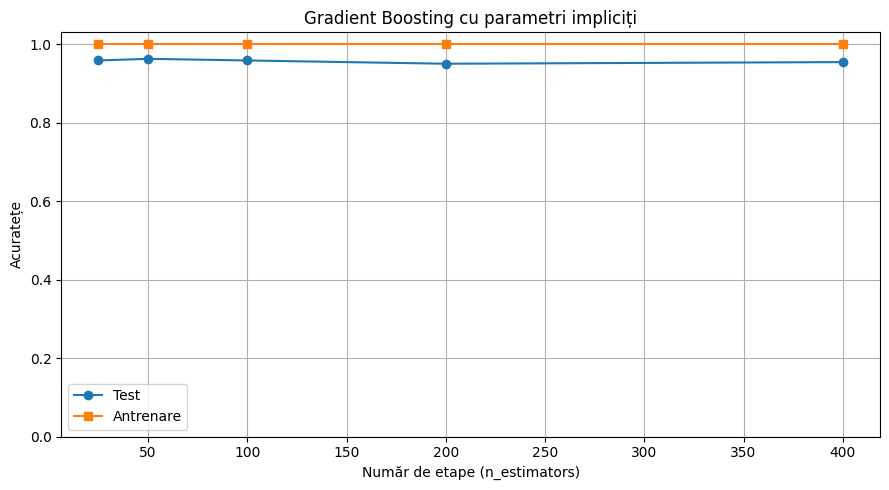

In [4]:
n_estimators_list = [25, 50, 100, 200, 400]
gb_rows = []
for n in n_estimators_list:
    start = perf_counter()
    model = GradientBoostingClassifier(n_estimators=n, random_state=RANDOM_STATE)
    model.fit(X_train, y_train)
    gb_rows.append({'n_estimators': n,
                    'Accuracy antrenare': accuracy_score(y_train, model.predict(X_train)),
                    'Accuracy test': accuracy_score(y_test, model.predict(X_test)),
                    'Secunde': perf_counter() - start})
    print(f"{n} etape: accuracy test = {gb_rows[-1]['Accuracy test']:.4f}", flush=True)
gb_curve = pd.DataFrame(gb_rows)
display(gb_curve.round(4))
fig, ax = plt.subplots()
ax.plot(gb_curve['n_estimators'], gb_curve['Accuracy test'], marker='o', label='Test')
ax.plot(gb_curve['n_estimators'], gb_curve['Accuracy antrenare'], marker='s', label='Antrenare')
ax.set(title='Gradient Boosting cu parametri impliciți', xlabel='Număr de etape (n_estimators)', ylabel='Acuratețe')
ax.set_ylim(0, 1.03)
ax.legend()
plt.tight_layout()
plt.show()

## Întrebarea 4 — Gradient Boosting cu GridSearchCV

Testăm 32 de combinații: 2 numere de estimatori × 2 rate de învățare × 2 fracții
de subeșantionare × 2 limite de caracteristici. Folosim 3 fold-uri stratificate,
`accuracy` pentru selecție și `refit=True` pentru reantrenarea configurației câștigătoare.
Grila este intenționat compactă, conform recomandării din enunț; nu reprezintă o
căutare exhaustivă a hiperparametrilor posibili.

`learning_rate` controlează contribuția fiecărei etape, `subsample=0.5` introduce
boosting stocastic, iar `max_features` limitează caracteristicile candidate la separare.

In [5]:
gb_param_grid = {
    'n_estimators': [100, 200],
    'learning_rate': [0.01, 0.1],
    'subsample': [0.5, 1.0],
    'max_features': [2, 4],
}
gb_search = GridSearchCV(
    GradientBoostingClassifier(random_state=RANDOM_STATE),
    gb_param_grid, scoring='accuracy', cv=cv, n_jobs=1, refit=True, error_score='raise',
)
start = perf_counter()
gb_search.fit(X_train, y_train)
print(f'Timp căutare Gradient Boosting: {perf_counter() - start:.1f} secunde')
print('Parametri optimi:', gb_search.best_params_)
print(f'Accuracy medie CV: {gb_search.best_score_:.4f}')
display(pd.DataFrame(gb_search.cv_results_).sort_values('rank_test_score')[
    ['params', 'mean_test_score', 'std_test_score', 'rank_test_score']
].head(8))
best_gb = gb_search.best_estimator_

Timp căutare Gradient Boosting: 50.1 secunde
Parametri optimi: {'learning_rate': 0.1, 'max_features': 4, 'n_estimators': 200, 'subsample': 0.5}
Accuracy medie CV: 0.9448


,params,mean_test_score,std_test_score,rank_test_score
14,"{'learning_rate': 0.1, 'max_features': 4, 'n_e...",0.944792,0.025173,1
15,"{'learning_rate': 0.1, 'max_features': 4, 'n_e...",0.942708,0.010623,2
13,"{'learning_rate': 0.1, 'max_features': 4, 'n_e...",0.939583,0.007795,3
10,"{'learning_rate': 0.1, 'max_features': 2, 'n_e...",0.934375,0.007655,4
11,"{'learning_rate': 0.1, 'max_features': 2, 'n_e...",0.933333,0.019819,5
12,"{'learning_rate': 0.1, 'max_features': 4, 'n_e...",0.928125,0.013258,6
9,"{'learning_rate': 0.1, 'max_features': 2, 'n_e...",0.917708,0.019151,7
8,"{'learning_rate': 0.1, 'max_features': 2, 'n_e...",0.912500,0.006751,8


,Accuracy,Eroare (1 − accuracy),Balanced accuracy,Precision macro,Recall macro,F1 macro,F1 weighted
Gradient Boosting,0.9708,0.0292,0.9692,0.9708,0.9692,0.9695,0.9708


Gradient Boosting — configurația selectată prin CV
                    precision    recall  f1-score   support

            LAYING     0.9783    1.0000    0.9890        45
           SITTING     1.0000    0.9286    0.9630        42
          STANDING     0.9565    1.0000    0.9778        44
           WALKING     1.0000    0.9750    0.9873        40
WALKING_DOWNSTAIRS     0.9688    0.9394    0.9538        33
  WALKING_UPSTAIRS     0.9211    0.9722    0.9459        36

          accuracy                         0.9708       240
         macro avg     0.9708    0.9692    0.9695       240
      weighted avg     0.9718    0.9708    0.9708       240



Prezis,LAYING,SITTING,STANDING,WALKING,WALKING_DOWNSTAIRS,WALKING_UPSTAIRS
Real,,,,,,
LAYING,45,0,0,0,0,0
SITTING,1,39,2,0,0,0
STANDING,0,0,44,0,0,0
WALKING,0,0,0,39,0,1
WALKING_DOWNSTAIRS,0,0,0,0,31,2
WALKING_UPSTAIRS,0,0,0,0,1,35


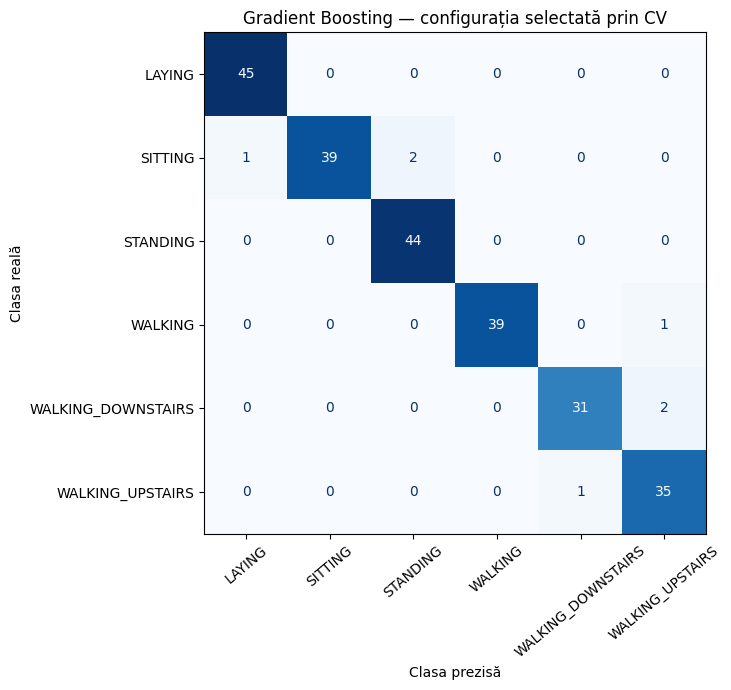

In [6]:
def metric_summary(model):
    prediction = model.predict(X_test)
    return {
        'Accuracy': accuracy_score(y_test, prediction),
        'Eroare (1 − accuracy)': 1 - accuracy_score(y_test, prediction),
        'Balanced accuracy': balanced_accuracy_score(y_test, prediction),
        'Precision macro': precision_score(y_test, prediction, average='macro', zero_division=0),
        'Recall macro': recall_score(y_test, prediction, average='macro', zero_division=0),
        'F1 macro': f1_score(y_test, prediction, average='macro', zero_division=0),
        'F1 weighted': f1_score(y_test, prediction, average='weighted', zero_division=0),
    }

def report_and_confusion(model, title):
    prediction = model.predict(X_test)
    print(title)
    print(classification_report(y_test, prediction, labels=class_ids,
                                target_names=class_names, digits=4, zero_division=0))
    cm = confusion_matrix(y_test, prediction, labels=class_ids)
    display(pd.DataFrame(cm, index=class_names, columns=class_names)
            .rename_axis(index='Real', columns='Prezis'))
    fig, ax = plt.subplots(figsize=(9, 7))
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
        ax=ax, cmap='Blues', colorbar=False, values_format='d', xticks_rotation=40,
    )
    ax.set(title=title, xlabel='Clasa prezisă', ylabel='Clasa reală')
    ax.grid(False)
    plt.tight_layout()
    plt.show()
    return cm

display(pd.DataFrame([metric_summary(best_gb)], index=['Gradient Boosting']).round(4))
gb_cm = report_and_confusion(best_gb, 'Gradient Boosting — configurația selectată prin CV')

## Întrebarea 5 — AdaBoost cu GridSearchCV

Testăm `n_estimators` între 100 și 200, două rate de învățare și arbori de bază
cu adâncimi 1 și 2 (12 combinații, 3 fold-uri). Setăm `max_features=4` în arborele
de bază, conform sugestiei. Folosim parametrul actual `estimator` al AdaBoost.
Comparăm modelele pe același test și nu presupunem că observațiile eronate sunt
valori aberante: matricea de confuzie singură nu poate demonstra acest lucru.

Timp căutare AdaBoost: 18.1 secunde
Parametri optimi: {'estimator__max_depth': 2, 'learning_rate': 0.1, 'n_estimators': 200}
Accuracy medie CV: 0.9010


,params,mean_test_score,std_test_score,rank_test_score
8,"{'estimator__max_depth': 2, 'learning_rate': 0...",0.901042,0.013094,1
7,"{'estimator__max_depth': 2, 'learning_rate': 0...",0.883333,0.025173,2
11,"{'estimator__max_depth': 2, 'learning_rate': 1...",0.880208,0.009660,3
6,"{'estimator__max_depth': 2, 'learning_rate': 0...",0.871875,0.018400,4
10,"{'estimator__max_depth': 2, 'learning_rate': 1...",0.848958,0.001473,5
9,"{'estimator__max_depth': 2, 'learning_rate': 1...",0.826042,0.012587,6


,Accuracy,Eroare (1 − accuracy),Balanced accuracy,Precision macro,Recall macro,F1 macro,F1 weighted
Gradient Boosting,0.9708,0.0292,0.9692,0.9708,0.9692,0.9695,0.9708
AdaBoost,0.9083,0.0917,0.9068,0.9133,0.9068,0.9084,0.9084


AdaBoost — configurația selectată prin CV
                    precision    recall  f1-score   support

            LAYING     0.9773    0.9556    0.9663        45
           SITTING     0.8750    0.8333    0.8537        42
          STANDING     0.8511    0.9091    0.8791        44
           WALKING     0.9048    0.9500    0.9268        40
WALKING_DOWNSTAIRS     1.0000    0.8485    0.9180        33
  WALKING_UPSTAIRS     0.8718    0.9444    0.9067        36

          accuracy                         0.9083       240
         macro avg     0.9133    0.9068    0.9084       240
      weighted avg     0.9115    0.9083    0.9084       240



Prezis,LAYING,SITTING,STANDING,WALKING,WALKING_DOWNSTAIRS,WALKING_UPSTAIRS
Real,,,,,,
LAYING,43,1,1,0,0,0
SITTING,1,35,6,0,0,0
STANDING,0,4,40,0,0,0
WALKING,0,0,0,38,0,2
WALKING_DOWNSTAIRS,0,0,0,2,28,3
WALKING_UPSTAIRS,0,0,0,2,0,34


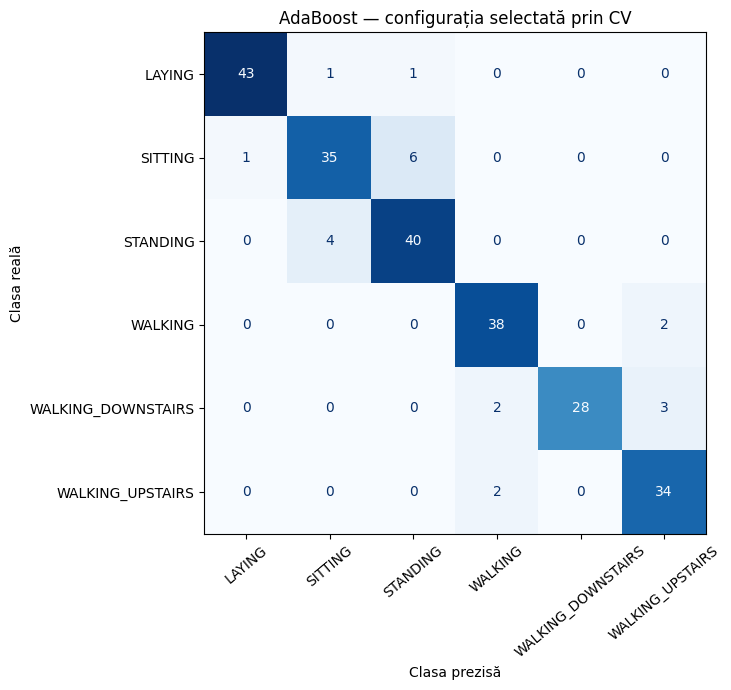

In [7]:
ada_param_grid = {
    'n_estimators': [100, 150, 200],
    'learning_rate': [0.1, 1.0],
    'estimator__max_depth': [1, 2],
}
ada_search = GridSearchCV(
    AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_features=4, random_state=RANDOM_STATE),
        random_state=RANDOM_STATE,
    ),
    ada_param_grid, scoring='accuracy', cv=cv, n_jobs=1, refit=True, error_score='raise',
)
start = perf_counter()
ada_search.fit(X_train, y_train)
print(f'Timp căutare AdaBoost: {perf_counter() - start:.1f} secunde')
print('Parametri optimi:', ada_search.best_params_)
print(f'Accuracy medie CV: {ada_search.best_score_:.4f}')
display(pd.DataFrame(ada_search.cv_results_).sort_values('rank_test_score')[
    ['params', 'mean_test_score', 'std_test_score', 'rank_test_score']
].head(6))
best_ada = ada_search.best_estimator_
display(pd.DataFrame({'Gradient Boosting': metric_summary(best_gb),
                      'AdaBoost': metric_summary(best_ada)}).T.round(4))
ada_cm = report_and_confusion(best_ada, 'AdaBoost — configurația selectată prin CV')

In [8]:
def confusion_pairs(cm, count=5):
    pairs = [(int(cm[i, j]), class_names[i], class_names[j])
             for i in class_ids for j in class_ids if i != j and cm[i, j] > 0]
    return pd.DataFrame(sorted(pairs, reverse=True)[:count],
                        columns=['Număr erori', 'Activitate reală', 'Activitate prezisă'])

print('Cele mai frecvente confuzii — Gradient Boosting:')
display(confusion_pairs(gb_cm))
print('Cele mai frecvente confuzii — AdaBoost:')
display(confusion_pairs(ada_cm))
gb_acc, ada_acc = accuracy_score(y_test, best_gb.predict(X_test)), accuracy_score(y_test, best_ada.predict(X_test))
display(Markdown(
    f'Pe acest test, accuracy este **{gb_acc:.2%}** pentru Gradient Boosting și '
    f'**{ada_acc:.2%}** pentru AdaBoost. Diferența (GB − AdaBoost) este '
    f'**{100 * (gb_acc - ada_acc):.2f} puncte procentuale**. '
    'Tabelele de confuzii indică activitățile confundate efectiv în această rulare; '
    'nu preluăm automat concluziile numerice din exemplul de exerciții.'
))

Cele mai frecvente confuzii — Gradient Boosting:


,Număr erori,Activitate reală,Activitate prezisă
0,2,WALKING_DOWNSTAIRS,WALKING_UPSTAIRS
1,2,SITTING,STANDING
2,1,WALKING_UPSTAIRS,WALKING_DOWNSTAIRS
3,1,WALKING,WALKING_UPSTAIRS
4,1,SITTING,LAYING


Cele mai frecvente confuzii — AdaBoost:


,Număr erori,Activitate reală,Activitate prezisă
0,6,SITTING,STANDING
1,4,STANDING,SITTING
2,3,WALKING_DOWNSTAIRS,WALKING_UPSTAIRS
3,2,WALKING_UPSTAIRS,WALKING
4,2,WALKING_DOWNSTAIRS,WALKING


Pe acest test, accuracy este **97.08%** pentru Gradient Boosting și **90.83%** pentru AdaBoost. Diferența (GB − AdaBoost) este **6.25 puncte procentuale**. Tabelele de confuzii indică activitățile confundate efectiv în această rulare; nu preluăm automat concluziile numerice din exemplul de exerciții.

## Întrebarea 6 — Regresie logistică regularizată și VotingClassifier

Ajustăm regresia logistică cu penalizarea L2 implicită, căutând `C ∈ {0.01, 0.1, 1, 10}`
prin aceeași validare încrucișată. Un `C` mic înseamnă regularizare mai puternică.
`StandardScaler` se află în pipeline, deci statisticile sunt estimate separat în
fiecare fold, fără acces la validare.

Combinăm regresia logistică, Gradient Boosting și AdaBoost prin **soft voting cu
ponderi egale**, adică media probabilităților estimate. Folosim configurațiile
selectate anterior. Măsurăm și scorul CV al ansamblului, apoi îl antrenăm pe tot
setul de antrenare.

Deși titlul laboratorului menționează stacking, `VotingClassifier` cerut de enunț
implementează voting. Stacking propriu-zis ar antrena un meta-model pe predicții
out-of-fold; aici nu există un astfel de meta-model.

Parametri optimi regresie logistică: {'lr__C': 1.0}
Accuracy medie CV: 0.9365


,param_lr__C,mean_test_score,std_test_score
0,0.01,0.934375,0.006751
1,0.10,0.932292,0.003898
2,1.00,0.936458,0.001473
3,10.00,0.931250,0.002552


,Accuracy,Eroare (1 − accuracy),Balanced accuracy,Precision macro,Recall macro,F1 macro,F1 weighted
Regresie logistică,0.95,0.05,0.9516,0.9521,0.9516,0.9517,0.9498


Regresie logistică regularizată
                    precision    recall  f1-score   support

            LAYING     0.9783    1.0000    0.9890        45
           SITTING     0.9024    0.8810    0.8916        42
          STANDING     0.9091    0.9091    0.9091        44
           WALKING     0.9512    0.9750    0.9630        40
WALKING_DOWNSTAIRS     1.0000    1.0000    1.0000        33
  WALKING_UPSTAIRS     0.9714    0.9444    0.9577        36

          accuracy                         0.9500       240
         macro avg     0.9521    0.9516    0.9517       240
      weighted avg     0.9498    0.9500    0.9498       240



Prezis,LAYING,SITTING,STANDING,WALKING,WALKING_DOWNSTAIRS,WALKING_UPSTAIRS
Real,,,,,,
LAYING,45,0,0,0,0,0
SITTING,1,37,4,0,0,0
STANDING,0,4,40,0,0,0
WALKING,0,0,0,39,0,1
WALKING_DOWNSTAIRS,0,0,0,0,33,0
WALKING_UPSTAIRS,0,0,0,2,0,34


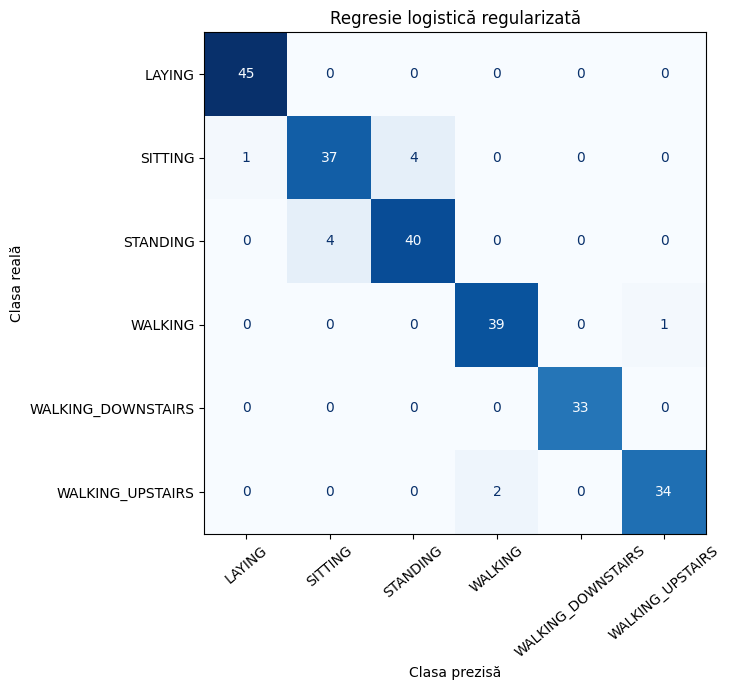

In [9]:
lr_pipeline = Pipeline([
    ('scale', StandardScaler()),
    ('lr', LogisticRegression(solver='lbfgs', max_iter=3000, random_state=RANDOM_STATE)),
])
lr_search = GridSearchCV(lr_pipeline, {'lr__C': [0.01, 0.1, 1.0, 10.0]},
                         scoring='accuracy', cv=cv, n_jobs=1, refit=True, error_score='raise')
lr_search.fit(X_train, y_train)
best_lr = lr_search.best_estimator_
print('Parametri optimi regresie logistică:', lr_search.best_params_)
print(f'Accuracy medie CV: {lr_search.best_score_:.4f}')
display(pd.DataFrame(lr_search.cv_results_)[['param_lr__C', 'mean_test_score', 'std_test_score']])
display(pd.DataFrame([metric_summary(best_lr)], index=['Regresie logistică']).round(4))
lr_cm = report_and_confusion(best_lr, 'Regresie logistică regularizată')

Accuracy CV voting, pe fold-uri: [0.9594 0.9312 0.9562]
Accuracy medie CV voting: 0.9490
                    precision    recall  f1-score   support

            LAYING     0.9783    1.0000    0.9890        45
           SITTING     0.9286    0.9286    0.9286        42
          STANDING     0.9535    0.9318    0.9425        44
           WALKING     0.9512    0.9750    0.9630        40
WALKING_DOWNSTAIRS     1.0000    0.9697    0.9846        33
  WALKING_UPSTAIRS     0.9444    0.9444    0.9444        36

          accuracy                         0.9583       240
         macro avg     0.9593    0.9583    0.9587       240
      weighted avg     0.9584    0.9583    0.9583       240



,Accuracy CV,Accuracy,Eroare (1 − accuracy),Balanced accuracy,Precision macro,Recall macro,F1 macro,F1 weighted,Selectat prin CV
Soft voting,0.9490,0.9583,0.0417,0.9583,0.9593,0.9583,0.9587,0.9583,True
Gradient Boosting,0.9448,0.9708,0.0292,0.9692,0.9708,0.9692,0.9695,0.9708,False
Regresie logistică,0.9365,0.9500,0.0500,0.9516,0.9521,0.9516,0.9517,0.9498,False
AdaBoost,0.9010,0.9083,0.0917,0.9068,0.9133,0.9068,0.9084,0.9084,False


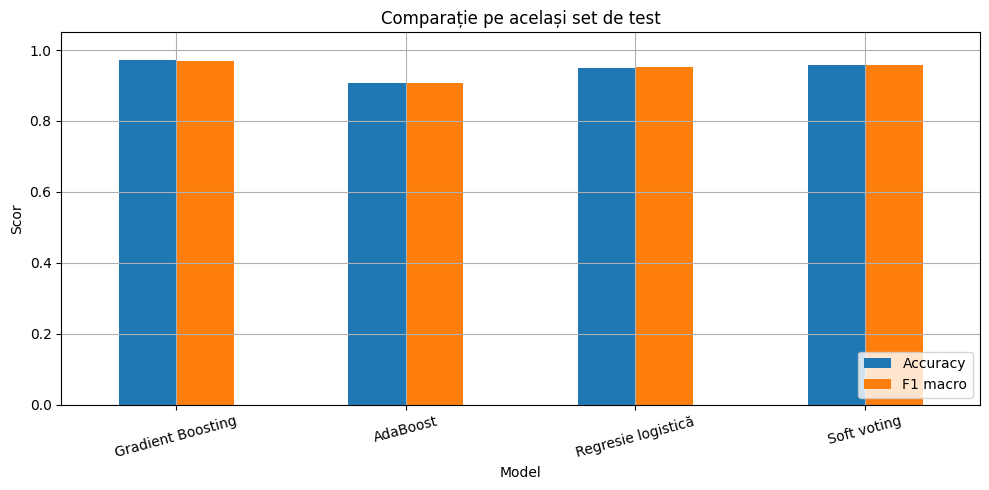

Model final selectat prin CV — Soft voting
                    precision    recall  f1-score   support

            LAYING     0.9783    1.0000    0.9890        45
           SITTING     0.9286    0.9286    0.9286        42
          STANDING     0.9535    0.9318    0.9425        44
           WALKING     0.9512    0.9750    0.9630        40
WALKING_DOWNSTAIRS     1.0000    0.9697    0.9846        33
  WALKING_UPSTAIRS     0.9444    0.9444    0.9444        36

          accuracy                         0.9583       240
         macro avg     0.9593    0.9583    0.9587       240
      weighted avg     0.9584    0.9583    0.9583       240



Prezis,LAYING,SITTING,STANDING,WALKING,WALKING_DOWNSTAIRS,WALKING_UPSTAIRS
Real,,,,,,
LAYING,45,0,0,0,0,0
SITTING,1,39,2,0,0,0
STANDING,0,3,41,0,0,0
WALKING,0,0,0,39,0,1
WALKING_DOWNSTAIRS,0,0,0,0,32,1
WALKING_UPSTAIRS,0,0,0,2,0,34


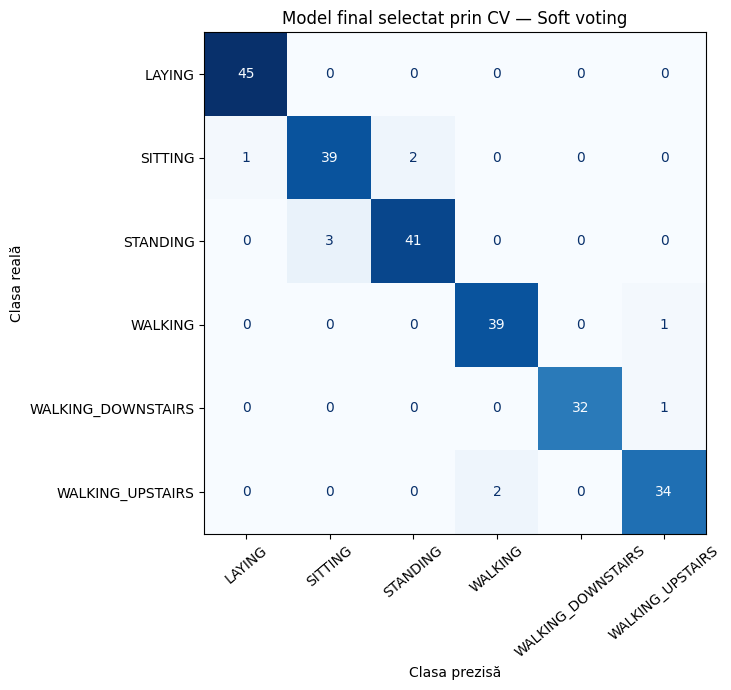

In [10]:
voting = VotingClassifier(
    estimators=[('lr', clone(best_lr)), ('gb', clone(best_gb)), ('ada', clone(best_ada))],
    voting='soft', n_jobs=1,
)
voting_cv = cross_val_score(voting, X_train, y_train, scoring='accuracy', cv=cv, n_jobs=1,
                            error_score='raise')
voting.fit(X_train, y_train)
print('Accuracy CV voting, pe fold-uri:', np.round(voting_cv, 4))
print(f'Accuracy medie CV voting: {voting_cv.mean():.4f}')
print(classification_report(y_test, voting.predict(X_test), labels=class_ids,
                            target_names=class_names, digits=4, zero_division=0))

models = {'Gradient Boosting': best_gb, 'AdaBoost': best_ada,
          'Regresie logistică': best_lr, 'Soft voting': voting}
cv_scores = {'Gradient Boosting': gb_search.best_score_, 'AdaBoost': ada_search.best_score_,
             'Regresie logistică': lr_search.best_score_, 'Soft voting': voting_cv.mean()}
comparison = pd.DataFrame({name: metric_summary(model) for name, model in models.items()}).T
comparison.insert(0, 'Accuracy CV', pd.Series(cv_scores))
best_name = max(cv_scores, key=cv_scores.get)
comparison['Selectat prin CV'] = comparison.index == best_name
display(comparison.sort_values('Accuracy CV', ascending=False).round(4))
fig, ax = plt.subplots(figsize=(10, 5))
comparison[['Accuracy', 'F1 macro']].plot.bar(ax=ax, rot=15)
ax.set(title='Comparație pe același set de test', ylabel='Scor', ylim=(0, 1.05), xlabel='Model')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()
final_cm = report_and_confusion(models[best_name], f'Model final selectat prin CV — {best_name}')

**Limitele selecției.** Folosim scorurile CV pentru alegerea modelului final, nu
scorurile de test. Scorurile CV după căutarea hiperparametrilor pot fi optimiste,
mai ales pentru voting, ale cărui componente au fost deja selectate pe aceleași
date. O estimare independentă a întregii proceduri ar necesita validare imbricată.
Testul este folosit pentru comparațiile cerute; nu ajustăm hiperparametri sau ponderi
după aceste rezultate. Eșantionul redus, împărțirea pe rânduri și o singură împărțire
limitează generalizarea concluziilor.

**Metrici.** Raportăm accuracy și eroarea sa complementară, dar și F1 macro, pentru
ca fiecare activitate să contribuie egal. Balanced accuracy este media recall-ului
pe clase, egală aici cu recall macro. Rândurile matricelor sunt clase reale, iar
coloanele sunt predicții. Voting nu garantează îmbunătățirea: un model mai slab sau
probabilități slab calibrate pot afecta media probabilităților.

**Concluzii:** modelul ales prin CV este **Soft voting**, cu accuracy CV **0.9490**. Pe test obține accuracy **95.83%**, eroare **4.17%** și F1 macro **0.9587**. Voting are o diferență de accuracy de **-1.25 puncte procentuale** față de Gradient Boosting. Cea mai mare accuracy observată pe test aparține modelului **Gradient Boosting**; această observație este descriptivă și nu schimbă selecția prin CV.

Cea mai mare accuracy observată pe test — Gradient Boosting
                    precision    recall  f1-score   support

            LAYING     0.9783    1.0000    0.9890        45
           SITTING     1.0000    0.9286    0.9630        42
          STANDING     0.9565    1.0000    0.9778        44
           WALKING     1.0000    0.9750    0.9873        40
WALKING_DOWNSTAIRS     0.9688    0.9394    0.9538        33
  WALKING_UPSTAIRS     0.9211    0.9722    0.9459        36

          accuracy                         0.9708       240
         macro avg     0.9708    0.9692    0.9695       240
      weighted avg     0.9718    0.9708    0.9708       240



Prezis,LAYING,SITTING,STANDING,WALKING,WALKING_DOWNSTAIRS,WALKING_UPSTAIRS
Real,,,,,,
LAYING,45,0,0,0,0,0
SITTING,1,39,2,0,0,0
STANDING,0,0,44,0,0,0
WALKING,0,0,0,39,0,1
WALKING_DOWNSTAIRS,0,0,0,0,31,2
WALKING_UPSTAIRS,0,0,0,0,1,35


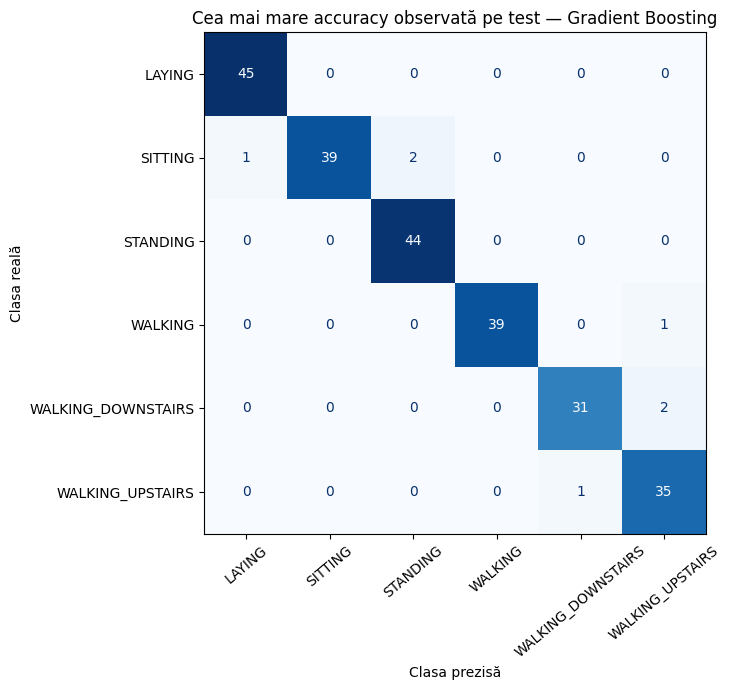

Verificări finale: metrici finite, clase reprezentate și toate observațiile de test evaluate.


In [11]:
final_metrics = comparison.loc[best_name]
best_test_name = comparison['Accuracy'].idxmax()
voting_delta = comparison.loc['Soft voting', 'Accuracy'] - comparison.loc['Gradient Boosting', 'Accuracy']
display(Markdown(
    f'**Concluzii:** modelul ales prin CV este **{best_name}**, cu accuracy CV '
    f'**{cv_scores[best_name]:.4f}**. Pe test obține accuracy '
    f'**{final_metrics["Accuracy"]:.2%}**, eroare **{final_metrics["Eroare (1 − accuracy)"]:.2%}** '
    f'și F1 macro **{final_metrics["F1 macro"]:.4f}**. '
    f'Voting are o diferență de accuracy de **{100 * voting_delta:.2f} puncte procentuale** '
    f'față de Gradient Boosting. Cea mai mare accuracy observată pe test aparține '
    f'modelului **{best_test_name}**; această observație este descriptivă și nu schimbă selecția prin CV.'
))
# Matrice suplimentară dacă liderul descriptiv de pe test diferă de modelul selectat prin CV.
if best_test_name != best_name:
    report_and_confusion(models[best_test_name], f'Cea mai mare accuracy observată pe test — {best_test_name}')

assert all(np.isfinite(list(metric_summary(model).values())).all() for model in models.values())
assert all(confusion_matrix(y_test, model.predict(X_test)).sum() == len(y_test) for model in models.values())
print('Verificări finale: metrici finite, clase reprezentate și toate observațiile de test evaluate.')